# TNT candidates v4 -- `400k-sh-wt006.nd2`


**Cells from the membrane, not from the actin.** Cells come from **Cellpose-SAM on the membrane
channel** (nd2: Cy5, the WGA stain of Anna's slides; czi: AF647), with DAPI as a second channel. v3 grew DAPI nuclei over
the actin signal, which assigned lamellae to far-away nuclei inside clusters.

**A candidate must bridge a gap**: at least half of the line's middle lies **outside every cell**,
its two ends reach (within 3 um) **two different** cells, the detector's mask covers >= 70% of it,
and its z-profile peaks above the substrate (z0 projection dropped, substrate = bottom 1 um from
the first plane with cells).

**Lines** come from `DETECTOR`:
- `'union'` (default): v3's 5-sigma gap-noise lines **plus** lines of the FAST U-Net++ F-actin
  mask (Aljapur et al., J Cell Sci 2026; classes "actin & stress fibers" + "filopodia" > 0.5);
- `'gap'` or `'fast'` alone; `'vesselfm'` (vesselFM on a top-hat stack -- lost more arrows).

**Ranking** (`SCORE`): `'filo'` (default) = FAST's *filopodia* probability along the line -- TNTs
look like filopodia, stress fibres inside cells do not; `'contrast'` = v3's gap-sigma contrast.
One entry per cell pair, shown with its best passing line.

On Anna's arrows (wt002 + wt006, 8 TNTs):

| lines, ranking | pairs | wt002 ranks | wt006 ranks | top 5 / 10 / 20 |
|---|---|---|---|---|
| gap, contrast | 93 | 15, 3, 5, -, - | 11, 26, 19 | 2 / 2 / 5 |
| FAST, filo | 65 | 3, 5, 2, 16, - | 2, -, 15 | 4 / 4 / 6 |
| **union, filo** | 100 | 2, 6, 1, 25, - | 1, 9, 18 | 3 / 5 / 6 (7 by 25) |

wt002 arrow 5 is lost by design: its tube runs over a cluster, inside a Cellpose cell. The 3 um
reach and the 0.5 gap threshold were chosen while looking at these arrows; the filopodia score
was not (it comes from a model trained elsewhere).


In [ ]:
# Cell 1 - imports, config, load
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import v4_utils as v4                          # also puts ../experiments, ../experiments_hough_v2/v3 on sys.path
import hough_v3_utils as h3
import gt_utils
import nd2_utils as nu
import importlib
importlib.reload(v4); importlib.reload(h3); importlib.reload(gt_utils); importlib.reload(nu)

NAME     = '400k-sh-wt006'
DETECTOR = 'union'                             # 'union' (gap + FAST, default), 'gap', 'fast' or 'vesselfm'
SCORE    = 'filo'                              # ranking: 'filo' (FAST filopodia prob, default) or 'contrast'
DEVICE   = 'mps'
path     = os.path.join(nu.ND2_DIR, f'{NAME}.nd2')
meta     = nu.nd2_meta(path)
px_um, dz_um = meta['px_um'], meta['dz_um']
vols = {n: nu.load_channel(path, c) for n, c in [('DAPI', nu.DAPI), ('TRITC', nu.TRITC), ('Cy5', nu.CY5)]}
TUBE, MEMBRANE = 'TRITC', 'Cy5'                # lines on the actin channel; cells on the WGA membrane channel
DATASET, PREFIX = 'nd2', NAME
gt = nu.load_gt(path)                          # counts only; None for wt002
print(f'{NAME}.nd2  {vols[TUBE].shape} at {px_um:.4f} um/px, dz {dz_um} um; channels {meta["channels"]}')


400k-sh-wt006.nd2  (48, 1200, 1200) at 0.1833 um/px, dz 0.4 um; channels ['DAPI', 'TRITC', 'Cy5']


In [ ]:
# Cell 2 - stack geometry (v3): drop a z0 projection, substrate = bottom 1 um from the first plane with cells
G = h3.stack_geometry(vols[TUBE], dz_um, substrate_um=1.0)
SUBSTRATE, MID, LAYER = G['SUBSTRATE'], G['MID'], G['layer']
print(f'z0 {"is a PROJECTION, dropped" if G["is_projection"] else "is a real plane"} '
      f'(corr {G["corr_z0"]:.2f} vs best real plane {G["corr_best_real"]:.2f})')
print(f'cells z{G["first"]}-z{G["last"]};  SUBSTRATE = {SUBSTRATE};  MID = z{MID[0]}-z{MID[-1]}')


z0 is a PROJECTION, dropped (corr 0.95 vs best real plane 0.91)
cells z18-z35;  SUBSTRATE = [18, 19, 20];  MID = z21-z35


65 cells (Cellpose on Cy5), covering 38% of the image;  annotator counted 61 cells and 7 TNTs


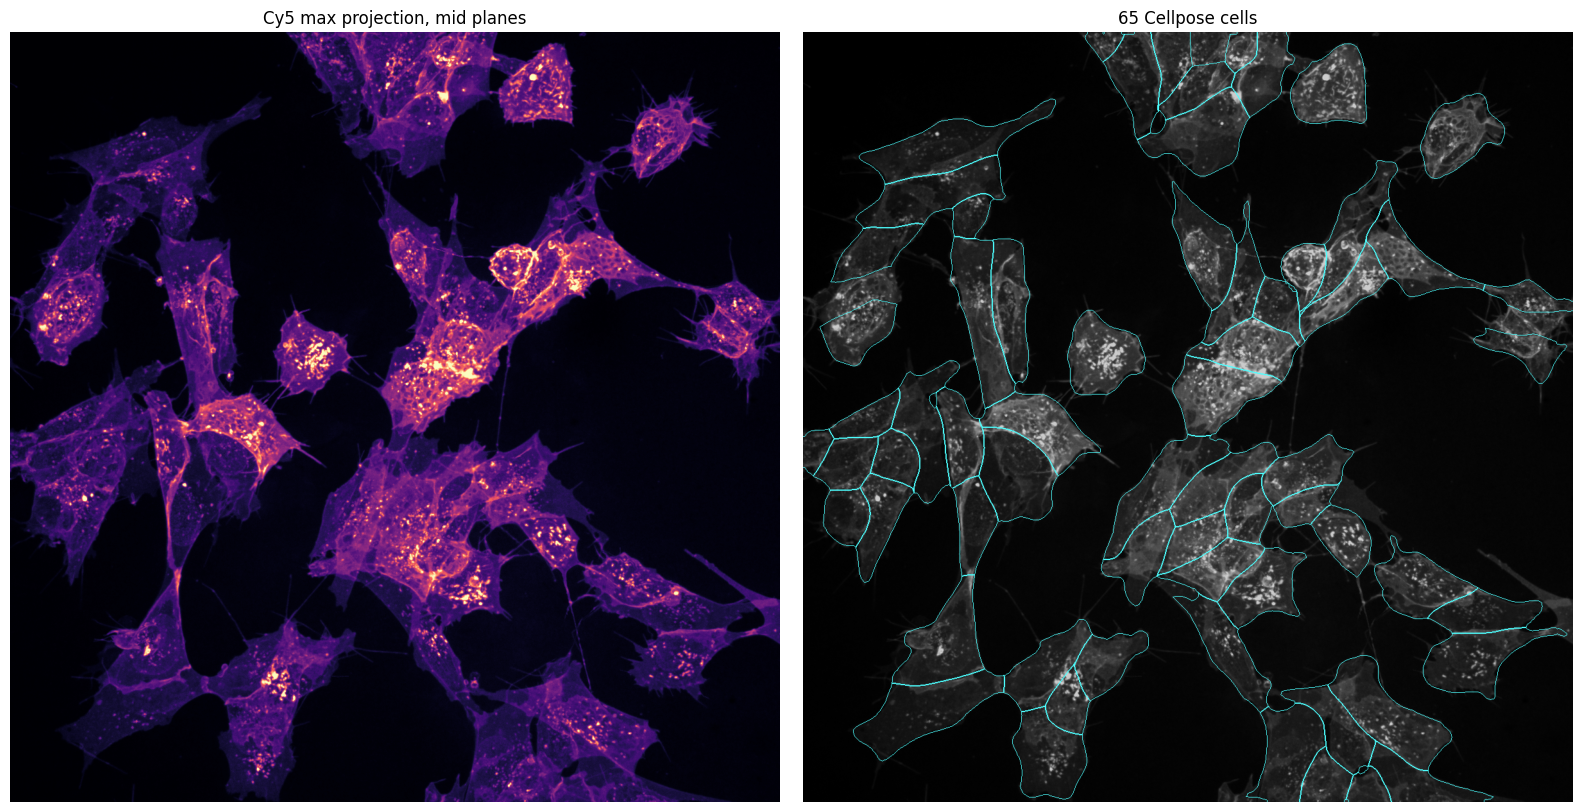

In [ ]:
# Cell 3 - cells: Cellpose-SAM on the membrane-channel projection, DAPI as 2nd channel
CELL_UM = 30.0                                 # expected cell diameter, sets Cellpose's scale
cells = v4.cells_from_membrane(vols[MEMBRANE], vols['DAPI'], MID, px_um, cell_um=CELL_UM,
                               cache=os.path.join(v4.CACHE_DIR, f'{PREFIX}_cellpose_{MEMBRANE.lower()}.npy'))
print(f'{cells.max()} cells (Cellpose on {MEMBRANE}), covering {(cells > 0).mean() * 100:.0f}% of the image'
      + (f';  annotator counted {gt.n_cells} cells and {gt.n_tnt} TNTs' if gt is not None else ';  no annotation'))

from skimage.segmentation import find_boundaries
CELL_EDGES = find_boundaries(cells, mode='inner')
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
mem = gt_utils._pnorm(vols[MEMBRANE][MID].max(0))
ax[0].imshow(mem, cmap='magma'); ax[0].set_title(f'{MEMBRANE} max projection, mid planes')
ov = np.repeat(mem[..., None], 3, 2) * 0.8; ov[CELL_EDGES] = (0.3, 1, 1)
ax[1].imshow(ov); ax[1].set_title(f'{cells.max()} Cellpose cells')
for a in ax: a.axis('off')
fig.tight_layout(); plt.show()


In [ ]:
# Cell 4 - per mid plane: lines (DETECTOR) -> bridge rule -> support -> above substrate; FAST scores every line
K_SIGMA, COVERAGE_MIN = 5.0, 0.7               # v3 detector settings
REACH_UM, FREE_MIN    = 3.0, 0.5               # ends within 3 um of two different cells; >= half the middle over a gap
from skimage.morphology import white_tophat, disk, dilation
from skimage.transform import probabilistic_hough_line

fast_model = v4.load_fast(DEVICE)
if DETECTOR == 'vesselfm':
    model = v4.load_vesselfm(DEVICE)
    th = np.stack([white_tophat(vols[TUBE][z].astype(np.float32), footprint=disk(round(1.5 / px_um)))
                   for z in LAYER])
    vprob = v4.vesselfm_probability(th, px_um, dz_um, model, device=DEVICE, pct=(1, 99.5),
                                    cache=os.path.join(v4.CACHE_DIR, f'{NAME}_vesselfm_tophat.npy'))
    VPROB = {z: vprob[i] for i, z in enumerate(LAYER)}

def hough(bw):
    return probabilistic_hough_line(bw, threshold=5, line_length=int(3 / px_um),
                                    line_gap=int(1.5 / px_um), rng=0)

sig = h3.sigma_volume(vols[TUBE], LAYER, cells > 0)
no_floor = np.zeros(cells.shape, bool)
rows, n_raw, n_bridge = [], 0, 0
for z in MID:
    d = h3.gap_lines(vols[TUBE][z], px_um, k_sigma=K_SIGMA)
    P = v4.fast_plane(fast_model, vols[TUBE][z], DEVICE)          # 5 class probabilities
    filament = P[1] + P[4]                                         # actin & stress fibres + filopodia
    sources = []
    if DETECTOR in ('gap', 'union'):
        sources.append(('gap', d['lines'], d['binary_dil']))
    if DETECTOR in ('fast', 'union'):
        bw = filament > 0.5
        sources.append(('fast', hough(bw), dilation(bw, disk(1))))
    if DETECTOR == 'vesselfm':
        bw = VPROB[z] > 0.5
        sources.append(('vesselfm', hough(bw), dilation(bw, disk(1))))
    for src, segs, support in sources:
        n_raw += len(segs)
        for seg in segs:
            pair, info = v4.bridge_test(seg, cells, px_um, reach_um=REACH_UM)
            if pair is None or info['free_frac'] < FREE_MIN:
                continue
            n_bridge += 1
            sup = h3.line_support(seg, support, d['fg'], px_um)
            if sup['coverage'] < COVERAGE_MIN:
                continue
            f = h3.line_features(seg, z, sig, LAYER, SUBSTRATE, cells > 0, no_floor, px_um, dz_um)
            if f['z_peak'] in SUBSTRATE:
                continue
            (x0, y0), (x1, y1) = seg
            rows.append(dict(src=src, z=z, pair=tuple(sorted(pair)), x0=x0, y0=y0, x1=x1, y1=y1,
                             filo=v4.mean_along(P[4], seg), fibres=v4.mean_along(P[1], seg),
                             lamelli=v4.mean_along(P[3], seg),
                             contrast=h3.line_contrast(seg, d['tophat'], d['gap_median'], d['gap_sigma']),
                             **info, **sup, elev_um=f['elev_um'], length_um=f['length_um']))
lines = pd.DataFrame(rows)
lines['score'] = lines[SCORE]
print(f'{n_raw} lines ({DETECTOR}) -> {n_bridge} bridge two cells over a gap -> {len(lines)} supported and '
      f'above the substrate ({lines.pair.nunique() if len(lines) else 0} cell pairs)')
print(lines.groupby('src').pair.agg(['size', 'nunique']).rename(columns={'size': 'lines', 'nunique': 'pairs'}))


143385 lines (union) -> 2474 bridge two cells over a gap -> 1816 supported and above the substrate (63 cell pairs)
      lines  pairs
src               
fast    612     38
gap    1204     58


In [ ]:
# Cell 5 - one entry per cell pair, represented by its best passing line
pairs = (lines.sort_values('score', ascending=False).drop_duplicates('pair')
         .assign(n_lines=lambda d: d.pair.map(lines.pair.value_counts()))
         .reset_index(drop=True))
pairs.index += 1
cols = ['pair', 'score', 'src', 'z', 'filo', 'fibres', 'contrast', 'length_um', 'free_frac', 'coverage', 'n_lines']
print(pairs[cols].head(30).round(2).to_string())


        pair  score   src   z  filo  fibres  contrast  length_um  free_frac  coverage  n_lines
1   (22, 26)   1.00  fast  28  1.00    0.00    106.38       4.41       1.00      1.00       49
2   (25, 32)   1.00  fast  30  1.00    0.00    548.45       6.50       0.98      1.00       64
3   (16, 21)   1.00  fast  35  1.00    0.00     84.75       3.85       1.00      1.00       11
4    (9, 12)   0.75   gap  27  0.75    0.00     27.04       5.47       1.00      0.95       51
5   (25, 28)   0.74  fast  25  0.74    0.26     74.76      15.58       0.77      1.00        2
6   (20, 26)   0.56   gap  26  0.56    0.12    362.28      16.04       0.75      0.95        2
7   (45, 48)   0.43   gap  28  0.43    0.00     20.84       8.18       1.00      1.00       68
8   (17, 24)   0.42   gap  32  0.42    0.12    298.60       5.94       1.00      1.00       56
9   (45, 57)   0.40   gap  25  0.40    0.15     49.77      26.28       1.00      0.96        3
10  (47, 54)   0.32   gap  25  0.32    0.00     49

In [ ]:
# Cell 6 - reference checks: Anna's arrows (nd2 wt002, wt006) and annotated pairs (czi, WEAK)
HIT_UM = 2.0
ARROWS = h3.load_arrows(NAME) if DATASET == 'nd2' else []
arrow_rows = []
for i, p in enumerate(ARROWS, 1):
    near = {r.pair for r in lines.itertuples()
            if h3.dist_to_segment(p, ((r.x0, r.y0), (r.x1, r.y1))) * px_um <= HIT_UM}
    ranks = sorted(int(k) for k, r in pairs.iterrows() if r.pair in near)
    arrow_rows.append(dict(arrow=i, x=p[0], y=p[1], inside_cell=int(cells[int(p[1]), int(p[0])]),
                           best_rank=ranks[0] if ranks else None))
if ARROWS:
    A = pd.DataFrame(arrow_rows); print(A.to_string(index=False))
    print(f'\nfound in the top 5 / 10 / 20: ' + ' / '.join(str(int((A.best_rank <= k).sum())) for k in (5, 10, 20))
          + f' of {len(A)} arrows   (inside_cell > 0: the tip lies inside a Cellpose cell -- excluded by design)')

# czi: annotators joined cell CENTRES, so only "which two cells" is usable -- a weak check, never a decision
GT_PAIRS, GT_ENDS, gt_rows = set(), np.zeros((0, 2, 2)), []
if DATASET == 'czi':
    sp = gt_utils.spatial_gt(path)
    GT_ENDS = sp['endpoints'] / DS
    rank_of = {r.pair: int(k) for k, r in pairs.iterrows()}
    for i, gp in enumerate(tp.gt_label_pairs(sp['endpoints'], cells, DS, verbose=False), 1):
        key = tuple(sorted(gp)) if gp else None
        gt_rows.append(dict(tnt=i, cells=key, rank=rank_of.get(key) if key else None))
    GT_PAIRS = {r['cells'] for r in gt_rows if r['cells']}
    R = pd.DataFrame(gt_rows); print(R.to_string(index=False))
    ranks = sorted({r['rank'] for r in gt_rows if r['rank']})
    print(f'\n{len(GT_PAIRS)} distinct annotated pairs ({gt.n_tnt} TNTs); in the top 5 / 10 / 20: '
          + ' / '.join(str(sum(r <= k for r in ranks)) for k in (5, 10, 20)) + f'  of {len(pairs)} listed pairs (weak labels)')
pairs['gt'] = pairs.pair.isin(GT_PAIRS)
if not ARROWS and DATASET != 'czi':
    print('no reference for this image')


 arrow     x     y  inside_cell  best_rank
     1 402.6 562.4            0          2
     2 864.8 897.7            0          9
     3 211.5 299.2            0         18

found in the top 5 / 10 / 20: 1 / 2 / 3 of 3 arrows   (inside_cell > 0: the tip lies inside a Cellpose cell -- excluded by design)


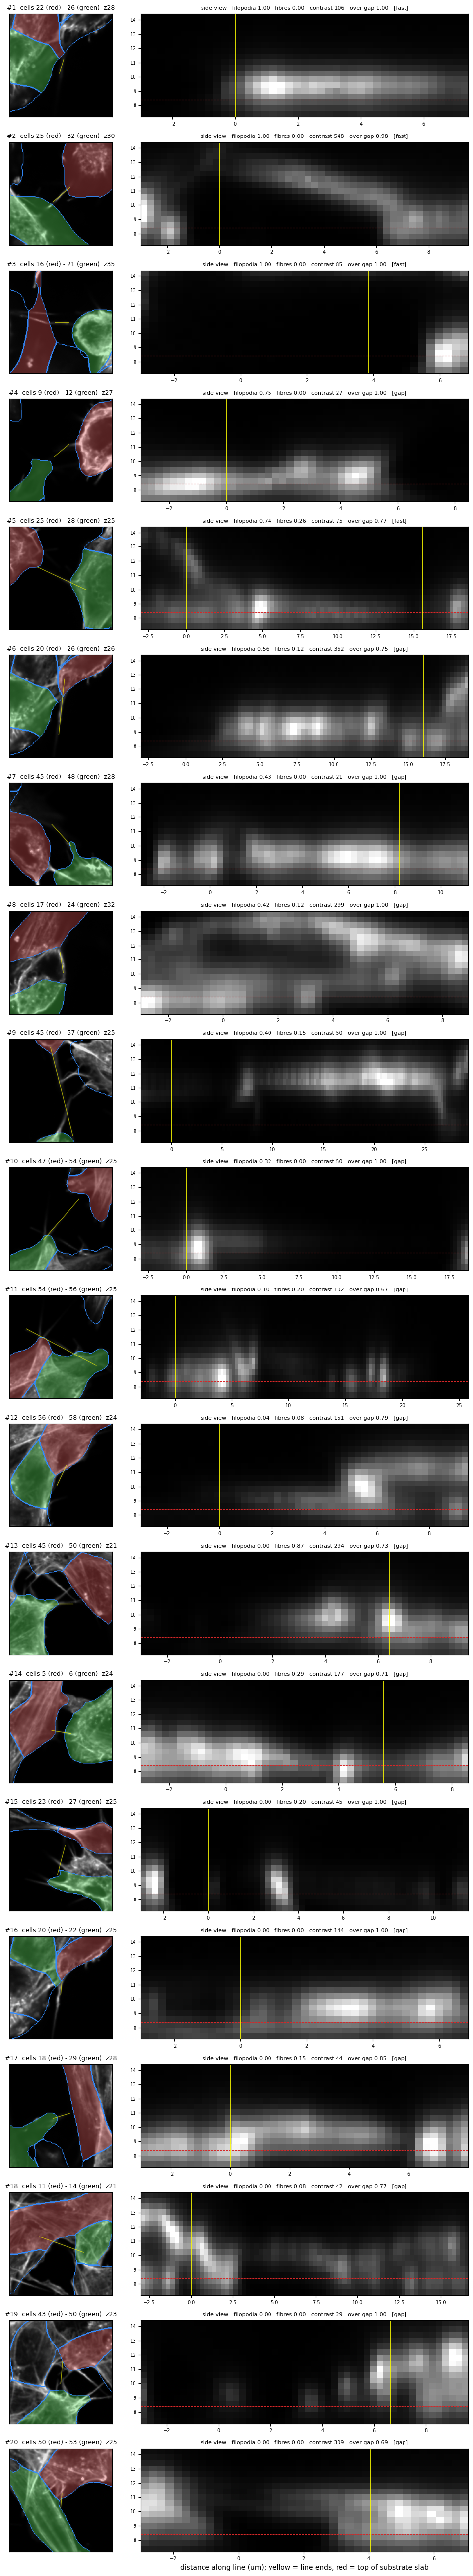

In [ ]:
# Cell 7 - review sheet: top-K pairs from above (Cellpose outlines, the two cells tinted) and from the side
K, CROP_UM = 20, 15.0
top = pairs.head(K)
if len(top):
    fig, axes = plt.subplots(len(top), 2, figsize=(10, 2.6 * len(top)),
                             gridspec_kw=dict(width_ratios=[1, 2.2]), squeeze=False)
    h = int(CROP_UM / px_um)
    for i, (rank, c) in enumerate(top.iterrows()):
        cy, cx = int((c.y0 + c.y1) / 2), int((c.x0 + c.x1) / 2)
        r0, c0 = max(cy - h, 0), max(cx - h, 0)
        sl = (slice(r0, cy + h), slice(c0, cx + h))
        crop = np.repeat(gt_utils._pnorm(vols[TUBE][int(c.z)])[sl][..., None], 3, 2) * 0.9
        for k, col in zip(c.pair, [(1, 0.35, 0.35), (0.35, 1, 0.35)]):
            m = (cells == k)[sl]; crop[m] = 0.7 * crop[m] + 0.3 * np.array(col)
        crop[CELL_EDGES[sl]] = (0.2, 0.55, 1)
        ax = axes[i, 0]
        ax.imshow(np.clip(crop, 0, 1))
        ax.plot([c.x0 - c0, c.x1 - c0], [c.y0 - r0, c.y1 - r0], '-', color='yellow', lw=1, alpha=0.6)
        ax.set_title(f'#{rank}  cells {c.pair[0]} (red) - {c.pair[1]} (green)  z{int(c.z)}'
                     + ('  [annotated]' if c['gt'] else ''), fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
        img, ext = h3.side_view(vols[TUBE], ((c.x0, c.y0), (c.x1, c.y1)), LAYER, px_um, dz_um)
        ext = (ext[0], ext[1], LAYER[0] * dz_um, (LAYER[-1] + 1) * dz_um)
        ax = axes[i, 1]
        ax.imshow(gt_utils._pnorm(img), cmap='gray', origin='lower', extent=ext, aspect='auto')
        ax.axhline((SUBSTRATE[-1] + 1) * dz_um, color='tab:red', lw=0.8, ls='--')
        ax.axvline(0, color='yellow', lw=0.6); ax.axvline(c.length_um, color='yellow', lw=0.6)
        ax.tick_params(labelsize=7)
        ax.set_title(f'side view   filopodia {c.filo:.2f}   fibres {c.fibres:.2f}   contrast {c.contrast:.0f}   over gap {c.free_frac:.2f}   [{c.src}]', fontsize=8)
    axes[-1, 1].set_xlabel('distance along line (um); yellow = line ends, red = top of substrate slab')
    fig.tight_layout()
    fig.savefig(os.path.join(v4.RESULTS_DIR, f'{PREFIX}_{DETECTOR}_{SCORE}_review.png'), dpi=100, bbox_inches='tight')
    plt.show()


In [ ]:
# Cell 8 - save for the summary notebook
summary = dict(dataset=DATASET, name=NAME, detector=DETECTOR, score=SCORE, projection_z0=bool(G['is_projection']), substrate=SUBSTRATE,
               mid=[MID[0], MID[-1]], cells=int(cells.max()),
               gt_cells=None if gt is None else int(gt.n_cells), gt_tnt=None if gt is None else int(gt.n_tnt),
               n_raw=int(n_raw), n_bridge=int(n_bridge), n_lines=int(len(lines)), n_pairs=int(len(pairs)),
               arrows=[{k: (None if v is None else float(v)) for k, v in a.items()} for a in arrow_rows],
               gt_pairs=len(GT_PAIRS), gt_pair_ranks=sorted({r['rank'] for r in gt_rows if r['rank']}))
json.dump(summary, open(os.path.join(v4.RESULTS_DIR, f'{PREFIX}_{DETECTOR}_{SCORE}_summary.json'), 'w'), indent=1)
lines.to_csv(os.path.join(v4.RESULTS_DIR, f'{PREFIX}_{DETECTOR}_{SCORE}_lines.csv'), index=False)
pairs.to_csv(os.path.join(v4.RESULTS_DIR, f'{PREFIX}_{DETECTOR}_{SCORE}_pairs.csv'), index_label='rank')
print(json.dumps({k: v for k, v in summary.items() if k not in ('arrows', 'gt_pair_ranks')}))


{"dataset": "nd2", "name": "400k-sh-wt006", "detector": "union", "score": "filo", "projection_z0": true, "substrate": [18, 19, 20], "mid": [21, 35], "cells": 65, "gt_cells": 61, "gt_tnt": 7, "n_raw": 143385, "n_bridge": 2474, "n_lines": 1816, "n_pairs": 63, "gt_pairs": 0}


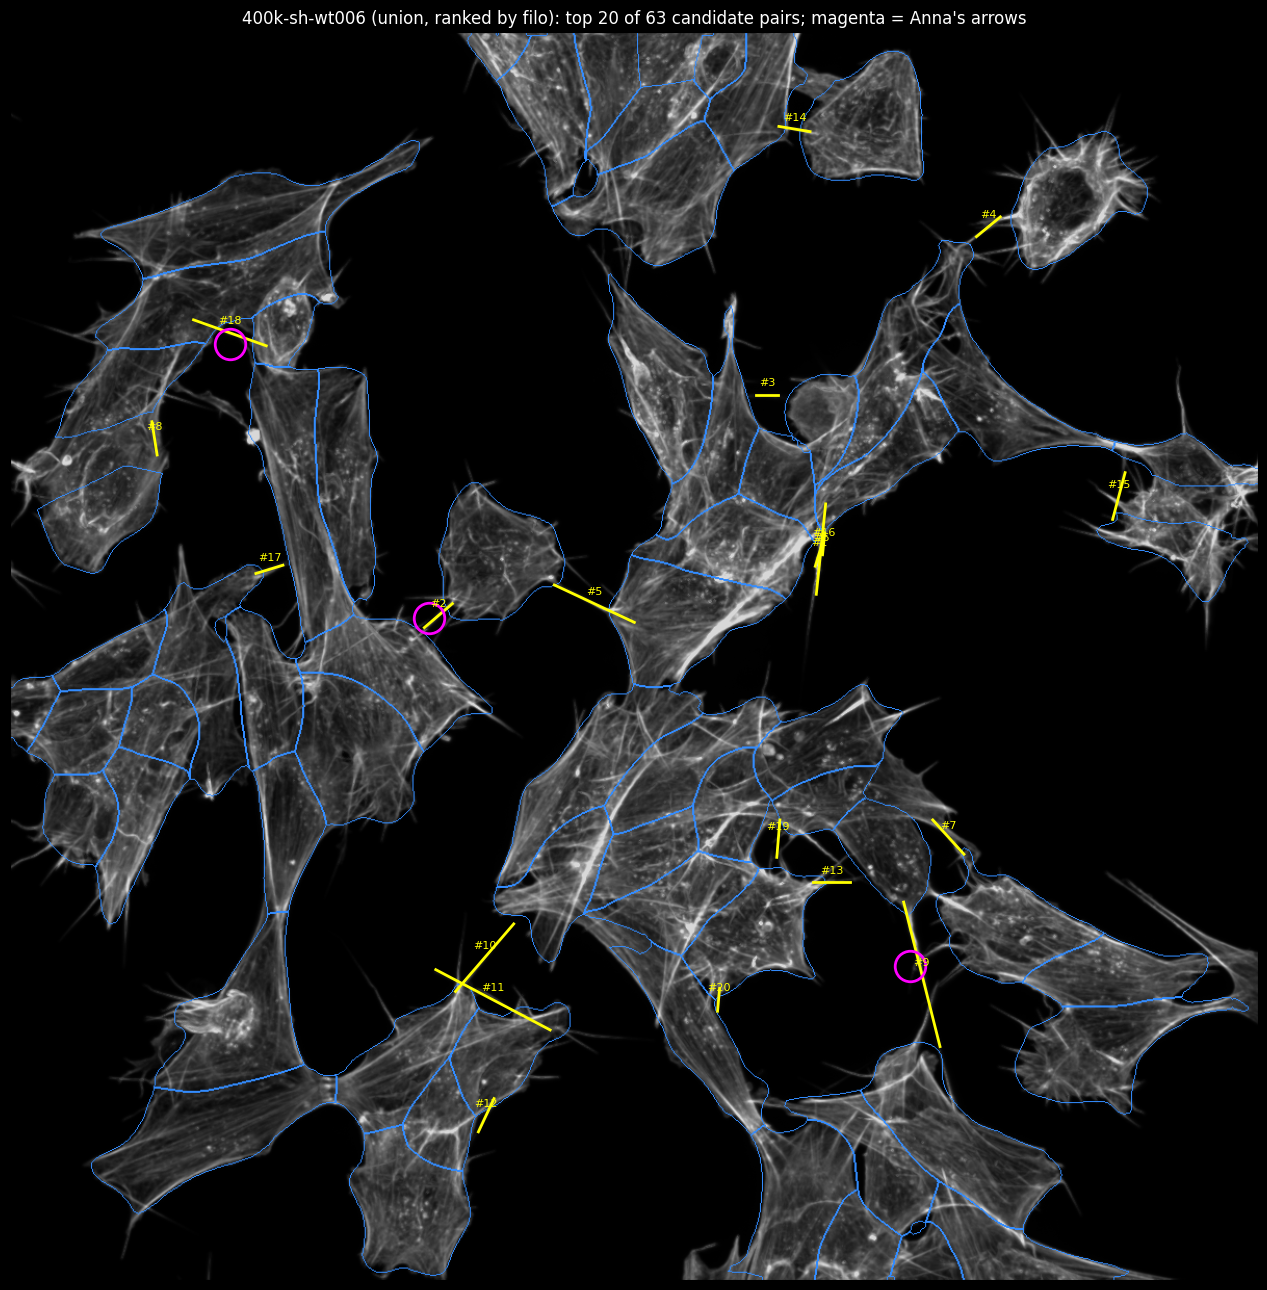

In [ ]:
# Cell 9 - overview: Cellpose cells (blue outlines), top 20 candidates (yellow, numbered), arrows (magenta)
fig, ax = plt.subplots(figsize=(13, 13), facecolor='black')
ov = np.repeat(gt_utils._pnorm(vols[TUBE][MID].max(0))[..., None], 3, 2) * 0.85
ov[CELL_EDGES] = (0.2, 0.55, 1)
ax.imshow(ov)
TOP_N = 20                                     # only the top-ranked candidates are drawn
for rank, c in pairs.head(TOP_N).iterrows():
    ax.plot([c.x0, c.x1], [c.y0, c.y1], '-', color='yellow', lw=2)
    ax.text((c.x0 + c.x1) / 2, (c.y0 + c.y1) / 2 - 8, f'#{rank}', color='yellow', fontsize=8, ha='center')
for x, y in ARROWS:
    ax.plot(x, y, 'o', mfc='none', mec='magenta', ms=22, mew=2)
for e in GT_ENDS:                              # czi annotation, centre to centre
    ax.plot(e[:, 1], e[:, 0], '-', color='lime', lw=1.5, alpha=0.8)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title(f'{NAME} ({DETECTOR}, ranked by {SCORE}): top {min(TOP_N, len(pairs))} of {len(pairs)} candidate pairs'
             + ('; magenta = Anna\'s arrows' if ARROWS else '') + ('; green = annotation' if len(GT_ENDS) else ''),
             color='white', fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(v4.RESULTS_DIR, f'{PREFIX}_{DETECTOR}_{SCORE}_overview.png'), dpi=110,
            facecolor='black', bbox_inches='tight')
plt.show()
